# 02 — Los costos del propietario

**La pregunta.** ¿Cuánto le queda al inversor después de pagar los costos del
inmueble, y esa renta le gana a una obligación negociable en dólares?

**Por qué importa.** Es el hallazgo central del trabajo y la base de **P1** (comprar o
no comprar). En la 2da entrega, la rentabilidad neta mediana (5,67%) ya quedaba por
debajo de la banda de retorno mínimo de 7,10% a 7,60%. Esa cifra tenía dos
simplificaciones que la devolución marcó:

- el **ABL** era un 3,80% plano para todas las propiedades (prioridad 4);
- no había **costos de entrada** ni **refacción** (prioridad 5).

Este notebook corrige las dos y mide cuánto se mueve el hallazgo.

**De dónde salen los números.** Las constantes, con fuente y fecha, están en
`src/supuestos.py`; las fórmulas, en `src/costos.py`; `src/kpis.py` las aplica al
dataset. Este notebook lee el dataset y recalcula en vivo lo que muestra.

1. El ABL segmentado · 2. Costos de entrada y TIR a 5 años · 3. La refacción y el
descuento de H3 · 4. Riesgo legal · 5. Sensibilidad · 6. Efecto sobre P3

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import costos as C
import eda
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
ok = df[(df["estimacion_confiable"] == 1) & df["rent_bruta_pct"].notna()].copy()
piso, techo = S.RETORNO_MIN_PISO_PCT, S.RETORNO_MIN_TECHO_PCT
print(f"Base: {len(ok):,} ventas con estimacion confiable. Banda de retorno minimo: {piso:.2f}% a {techo:.2f}%")

Base: 9,203 ventas con estimacion confiable. Banda de retorno minimo: 7.10% a 7.60%


## 1. El ABL segmentado

### 1.1 La fórmula

El ABL no es un porcentaje del alquiler: son dos tributos sobre la **Valuación Fiscal
Homogénea** (VFH) de cada partida, con escala progresiva y un coeficiente por barrio
(Ley Tarifaria 2026, Ley 6927, anexo, arts. 41 a 45). Antes de usar la fórmula, se
la valida contra un sistema externo: los ejemplos que calcula Roomix con la misma ley.

In [2]:
roomix = pd.DataFrame([(15e6, 0.75, 255_000), (15e6, 1.25, 285_000), (25e6, 0.75, 427_925),
                       (25e6, 1.75, 527_925), (40e6, 1.25, 781_575), (60e6, 1.25, 1_195_175),
                       (100e6, 1.75, 2_248_875)], columns=["VFH (ARS)", "coef. geografico", "Roomix (ARS/anio)"])
roomix["formula (ARS/anio)"] = C.abl_anual_ars(roomix["VFH (ARS)"], roomix["coef. geografico"],
                                               np.full(len(roomix), 1e15))
roomix["diferencia"] = roomix["formula (ARS/anio)"] - roomix["Roomix (ARS/anio)"]
roomix

,VFH (ARS),coef. geografico,Roomix (ARS/anio),formula (ARS/anio),diferencia
0,"15,000,000.00",0.75,255000,"255,000.00",0.00
1,"15,000,000.00",1.25,285000,"285,000.00",0.00
2,"25,000,000.00",0.75,427925,"427,925.00",0.00
3,"25,000,000.00",1.75,527925,"527,925.00",0.00
4,"40,000,000.00",1.25,781575,"781,575.00",0.00
5,"60,000,000.00",1.25,1195175,"1,195,175.00",0.00
6,"100,000,000.00",1.75,2248875,"2,248,875.00",0.00


**Lectura.** La fórmula reproduce los siete ejemplos al peso, incluido el recargo del
1% sobre la tasa a partir de $32 millones de VFH.

### 1.2 La VFH de cada propiedad

AGIP no publica la VFH por partida, así que se aproxima siguiendo cómo la define el
Código Fiscal (art. 288): parte del **valor de mercado por m² de la zona**, con un tope
del 20% del valor de mercado. Para cada venta:

> VFH = proporción × USD/m² mediano de su barrio y tipo de propiedad × su superficie

Así queda segmentada por **barrio, superficie y tipo**. La proporción no tiene fuente publicada: es una **estimación propia**,
calibrada para que la unidad de referencia de la 2da entrega (2 ambientes, 40 a 60 m²)
siga pagando 3,80%. El ajuste cambia **quién** paga más, no **cuánto** paga la unidad
de referencia; el nivel se prueba en la sensibilidad con la proporción en el tope legal.

In [3]:
modelo = joblib.load(f"{P}/modelo_alquiler.joblib")
print(f"Proporcion VFH / mercado calibrada: {modelo['proporcion_vfh']:.2%} "
      f"(tope legal {S.VFH_TOPE_SOBRE_MERCADO:.0%})")
ok[["abl_ars_mes", "abl_pct", "gastos_pct"]].describe(percentiles=[.1, .5, .9]).T[["10%", "50%", "90%"]]

Proporcion VFH / mercado calibrada: 14.99% (tope legal 20%)


,10%,50%,90%
abl_ars_mes,"21,496.40","45,821.00","117,784.00"
abl_pct,2.67,3.92,5.59
gastos_pct,12.91,14.16,15.83


### Gráfico 04 — ¿El ABL plano trata igual a propiedades que no son iguales?

El ABL como porcentaje del alquiler, por quintil de rentabilidad bruta: con el
porcentaje plano de la 2da entrega y con el ABL de cada propiedad.

guardado: ../graficos\04_abl_por_quintil.png


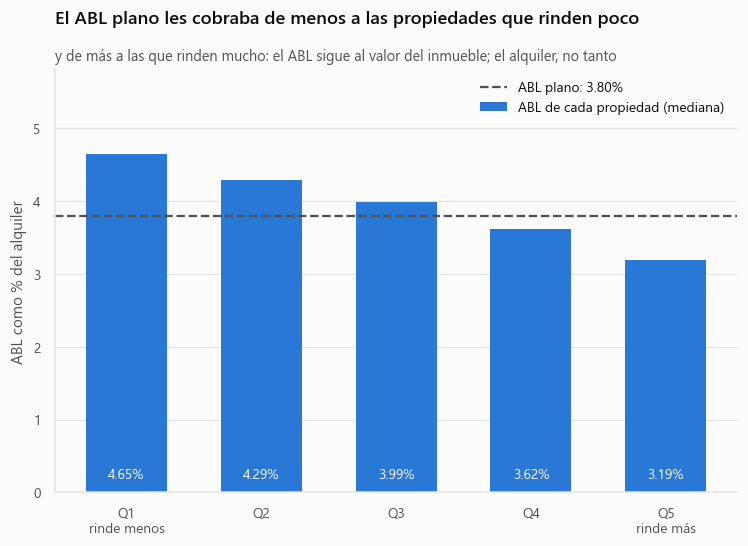

In [4]:
quintil = pd.qcut(ok["rent_bruta_pct"], 5, labels=["Q1\nrinde menos", "Q2", "Q3", "Q4", "Q5\nrinde más"])
q = ok.groupby(quintil, observed=True)["abl_pct"].median()

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(q))
ax.bar(x, q.values, width=0.6, color=eda.SERIE_1, label="ABL de cada propiedad (mediana)")
ax.axhline(S.ABL_PCT, color=eda.TINTA_2, linewidth=1.5, linestyle="--", label=f"ABL plano: {S.ABL_PCT:.2f}%")
# El valor va en la base de la barra: cerca del borde superior lo cruzaria la
# linea del ABL plano.
for xi, val in zip(x, q.values):
    ax.text(xi, 0.15, f"{val:.2f}%", ha="center", va="bottom", fontsize=9, color=eda.SUPERFICIE)
ax.set_xticks(x, q.index)
ax.set_ylabel("ABL como % del alquiler")
ax.set_ylim(0, q.max() * 1.25)
ax.legend(loc="upper right")
eda.titulo(ax, "El ABL plano les cobraba de menos a las propiedades que rinden poco",
           "y de más a las que rinden mucho: el ABL sigue al valor del inmueble; el alquiler, no tanto")
eda.guardar(fig, 4, "abl_por_quintil")
plt.show()

**Lectura.** El ABL sigue al valor del
inmueble y el alquiler no lo sigue en la misma proporción (H1), así que las unidades
caras, que rinden menos, pagan más ABL en proporción a su alquiler. En el quintil que
menos rinde el ABL se lleva 4,65% del alquiler; en el que más rinde, 3,19%. En
Constitución pesa 2,4%; en Palermo, 5,2%.

### 1.3 ¿Cuánto mueve la conclusión?

In [5]:
plano = (ok["rent_bruta_pct"] * (1 - S.VACANCIA_PCT / 100) * (1 - S.GASTOS_PCT / 100)).round(2)
en = ok.groupby("barrio")["barrio"].transform("size") >= S.MIN_VENTAS_BARRIO
b_plano = plano[en].groupby(ok.loc[en, "barrio"]).median()
b_segm = ok.loc[en].groupby("barrio")["rent_neta_pct"].median()
print(f"Neta mediana: {plano.median():.2f}% con ABL plano, {ok['rent_neta_pct'].median():.2f}% segmentado")
print(f"Spearman del ranking de barrios, plano contra segmentado: {b_plano.corr(b_segm, method='spearman'):.4f}")
mov = pd.DataFrame({"neta ABL plano": b_plano, "neta ABL segmentado": b_segm})
mov["puesto antes"] = mov["neta ABL plano"].rank(ascending=False, method="first").astype(int)
mov["puesto despues"] = mov["neta ABL segmentado"].rank(ascending=False, method="first").astype(int)
mov.sort_values("puesto despues").head(8)

Neta mediana: 5.67% con ABL plano, 5.65% segmentado
Spearman del ranking de barrios, plano contra segmentado: 0.9957


,neta ABL plano,neta ABL segmentado,puesto antes,puesto despues
barrio,,,,
constitucion,8.17,8.35,1,1
san cristobal,6.91,6.98,2,2
san telmo,6.76,6.85,3,3
liniers,6.71,6.80,5,4
balvanera,6.74,6.79,4,5
barracas,6.67,6.75,7,6
san nicolas,6.71,6.73,6,7
monserrat,6.55,6.59,8,8


**Lectura.** El ABL segmentado **redistribuye, pero no mueve la conclusión**: la neta
mediana baja dos centésimas y el ranking de barrios queda casi igual. Constitución sube
de 8,17% a 8,35%: es barato, y el plano le cobraba de más. El ajuste importa para
comparar propiedades entre sí; no cambia la respuesta de P1.

## 2. Costos de entrada y TIR a 5 años

### 2.1 Lo que cuesta comprar

Se pagan una vez, al comprar, y no vuelven al vender. Cada uno es un rango publicado;
el escenario **base** usa el piso de cada rango, así que el efecto que se informa es un
mínimo.

In [6]:
entrada = pd.DataFrame({
    "base (%)": [S.COMISION_COMPRADOR_PCT[0], S.ESCRIBANO_PCT[0], S.REGISTRALES_PCT[0],
                 S.SELLOS_ALICUOTA_REDUCIDA_PCT * S.SELLOS_PARTE_COMPRADOR],
    "alto (%)": [S.COMISION_COMPRADOR_PCT[1], S.ESCRIBANO_PCT[1], S.REGISTRALES_PCT[1],
                 S.SELLOS_ALICUOTA_PCT * S.SELLOS_PARTE_COMPRADOR],
    "fuente": ["CUCICBA, 09-01-2026", "La Nacion, 01-05-2026", "La Nacion, 01-05-2026",
               "Ley 6927, art. 34 (mitad del comprador)"],
}, index=["comision inmobiliaria", "escribano", "certificados e inscripcion", "sellos"])
display(entrada)
print(f"Sellos: {S.SELLOS_ALICUOTA_REDUCIDA_PCT}% hasta ARS {S.SELLOS_UMBRAL_ARS / 1e6:,.1f} millones de precio "
      f"(USD {S.SELLOS_UMBRAL_ARS / S.TC_ARS_USD:,.0f}), {S.SELLOS_ALICUOTA_PCT}% arriba.")
print(f"Costos de entrada, mediana de la base: {ok['costos_entrada_pct'].median():.2f}% del precio")

,base (%),alto (%),fuente
comision inmobiliaria,3.00,4.00,"CUCICBA, 09-01-2026"
escribano,1.00,2.00,"La Nacion, 01-05-2026"
certificados e inscripcion,0.20,0.40,"La Nacion, 01-05-2026"
sellos,1.35,1.75,"Ley 6927, art. 34 (mitad del comprador)"


Sellos: 2.7% hasta ARS 226.1 millones de precio (USD 150,733), 3.5% arriba.
Costos de entrada, mediana de la base: 5.55% del precio


### 2.2 La TIR a 5 años

Un costo que se paga una vez no se puede restar de una rentabilidad anual. Por eso se
suma una métrica:

> **TIR a 5 años:** la tasa anual que iguala lo que se pone al comprar (precio, costos
> de entrada y refacción) con lo que se recibe (5 años de alquiler neto y la reventa al
> mismo precio en dólares).

Es la cifra comparable con la banda de retorno mínimo, que es la TIR de una ON a un
plazo parecido. Sin costos de entrada coincide con la neta, y eso se verifica:

In [7]:
print("TIR con costo inicial 0 para netas de 5,65% y 7,10%:", C.tir([5.65, 7.10], [0, 0]).round(4))
print("TIR de una neta de 5,65% con 5,55% de costos de entrada:", C.tir([5.65], [5.55]).round(2))

TIR con costo inicial 0 para netas de 5,65% y 7,10%: [5.65 7.1 ]
TIR de una neta de 5,65% con 5,55% de costos de entrada: [4.39]


### Gráfico 05 — ¿Qué parte de la oferta le gana a una ON en dólares?

Distribución acumulada de la rentabilidad neta y de la TIR a 5 años de cada propiedad,
contra la banda de retorno mínimo.

guardado: ../graficos\05_neta_tir_contra_banda.png


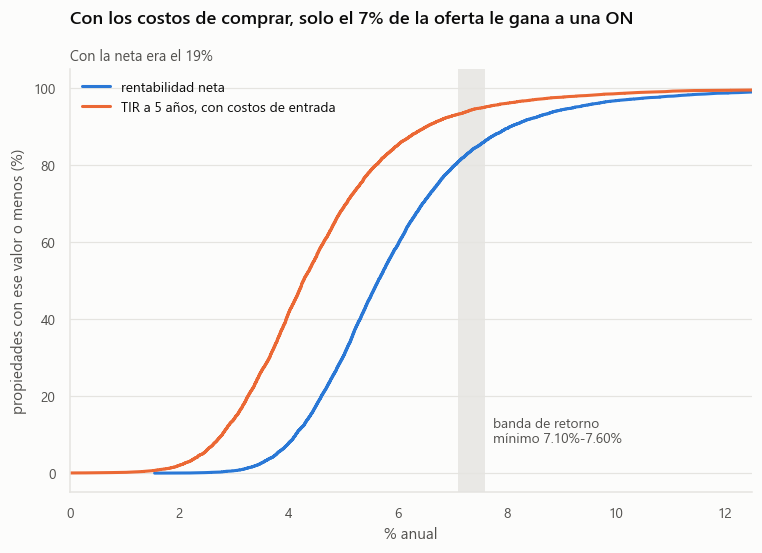

Sobre el piso de la banda: neta 19.4%, TIR 6.8%. Dentro del presupuesto del inversor (5,198 ventas): neta 14.7%, TIR 5.1%


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for serie, etiqueta, color in [(ok["rent_neta_pct"], "rentabilidad neta", eda.SERIE_1),
                               (ok["tir_5a_pct"], "TIR a 5 años, con costos de entrada", eda.SERIE_2)]:
    s = np.sort(serie.values)
    ax.plot(s, np.arange(1, len(s) + 1) / len(s) * 100, color=color, label=etiqueta)
ax.axvspan(piso, techo, color=eda.GRILLA, alpha=0.8, zorder=0)
ax.text(techo + 0.15, 8, f"banda de retorno\nmínimo {piso:.2f}%-{techo:.2f}%", fontsize=9, color=eda.TINTA_2)
ax.set_xlim(0, ok["rent_neta_pct"].quantile(.99))
ax.set_xlabel("% anual")
ax.set_ylabel("propiedades con ese valor o menos (%)")
ax.legend(loc="upper left")
neta_sobre, tir_sobre = (ok["rent_neta_pct"] >= piso).mean(), (ok["tir_5a_pct"] >= piso).mean()
eda.titulo(ax, f"Con los costos de comprar, solo el {tir_sobre:.0%} de la oferta le gana a una ON",
           f"Con la neta era el {neta_sobre:.0%}")
eda.guardar(fig, 5, "neta_tir_contra_banda")
plt.show()
pres = ok[ok["venta_usd"].between(*S.PRESUPUESTO_USD)]
print(f"Sobre el piso de la banda: neta {neta_sobre:.1%}, TIR {tir_sobre:.1%}. "
      f"Dentro del presupuesto del inversor ({len(pres):,} ventas): neta {(pres['rent_neta_pct'] >= piso).mean():.1%}, "
      f"TIR {(pres['tir_5a_pct'] >= piso).mean():.1%}")

**Lectura.** Los costos de entrada corren toda la distribución hacia la izquierda. Con
la rentabilidad neta, una de cada cinco propiedades superaba el piso de la banda; con
la TIR, una de cada quince. Dentro del presupuesto del inversor, de USD 80.000 a
200.000, la proporción cae de 14,7% a 5,1%.

In [9]:
with pd.option_context("display.max_colwidth", None):
    display(pd.read_csv(f"{P}/antes_despues_kpis.csv", encoding="utf-8-sig").set_index("escenario"))

,mediana_pct,barrios_sobre_piso,barrios,top5
escenario,,,,
"antes: neta, ABL plano",5.67,1,constitucion,constitucion; san cristobal; san telmo; balvanera; liniers
"neta, ABL segmentado",5.65,1,constitucion,constitucion; san cristobal; san telmo; liniers; balvanera
"TIR 5a, ABL segm. + entrada",4.27,0,NaN,constitucion; san telmo; san cristobal; liniers; san nicolas


**Lectura.** El ABL segmentado deja el hallazgo donde estaba; los costos de entrada lo
refuerzan. La TIR mediana es 4,27%, y **ningún barrio supera el piso de la banda**:
Constitución, el único que lo superaba con la neta, queda en 6,44%. La distancia entre
la propiedad mediana y una ON pasa de 1,45 a 2,83 puntos por año.

## 3. La refacción y el descuento de H3

En la 2da entrega, las unidades "a reciclar" cotizaban con un descuento de 23,3% en el
m² frente a comparables de su celda, pero sin el costo de refaccionarlas ese descuento
no se podía leer como oportunidad. Dos escenarios, porque las fuentes difieren por un
factor de cuatro:

- **mínima:** rehacer baño y cocina y pintar (Reporte Inmobiliario y Sui Color, vía La
  Nación, 30-03-2026);
- **integral:** instalaciones, aberturas, cocina, baños, pisos y pintura (RenovArqui,
  febrero de 2026, con IVA).

In [10]:
t3 = eda.efecto_estratificado(df[(df["operacion"] == "venta") & df["venta_m2_usd"].notna()], "a_reciclar",
                              "venta_m2_usd", ["barrio", "superficie_rango"], S.MIN_GRUPO_ESTRATO)
d = -eda.mediana_ponderada(t3["diferencia"] / t3["mediana_0"], t3["peso"])
umbral = d / (1 - d) * 100
rec = ok[ok["a_reciclar"] == 1]
print(f"Descuento del m2 a reciclar contra comparables: {d:.1%} en {len(t3)} celdas")
print(f"Sobre el precio de la unidad a reciclar equivale a {umbral:.1f}%: la refaccion tiene que costar menos que eso")
filas = []
for esc, nombre in [("base", "minima"), ("alto", "integral")]:
    r = C.refaccion_usd(rec, esc) / rec["venta_usd"] * 100
    filas.append({"refaccion": nombre, "costo mediano (% del precio)": r.median(),
                  "unidades donde el descuento la cubre (%)": (r < umbral).mean() * 100})
display(pd.DataFrame(filas).set_index("refaccion"))
sube = rec["alquiler_post_refaccion_usd_mes"] / rec["alquiler_est_usd_mes"] - 1
print(f"Alquiler estimado tras refaccionar: {sube.median():+.1%} (mediana de {len(rec)} unidades)")

Descuento del m2 a reciclar contra comparables: 23.3% en 35 celdas
Sobre el precio de la unidad a reciclar equivale a 30.3%: la refaccion tiene que costar menos que eso


,costo mediano (% del precio),unidades donde el descuento la cubre (%)
refaccion,,
minima,13.52,94.30
integral,83.35,0.00


Alquiler estimado tras refaccionar: +14.4% (mediana de 421 unidades)


**Lectura.** El descuento de las unidades a reciclar es una oportunidad **si la
refacción es mínima**: baño, cocina y pintura cuestan alrededor de 13% del precio, y
el descuento lo cubre en el 94% de las unidades. Si hay que rehacer todo, la obra
cuesta más que el descuento en todas. Refaccionada, la unidad se alquila 14% más
según el modelo, y ese beneficio entra en la TIR para no cobrar la obra sin su efecto.
No se descuentan los meses de obra sin alquiler.

## 4. Riesgo legal

**Limitación declarada, sin número.** Juicios de desalojo, inquilinos que no pagan,
cambios de régimen como los de la Ley 27.551 y el DNU 70/2023: no hay una fuente que
publique su frecuencia o su costo para CABA, y estimarlo sería peor que no tenerlo. No
entra en ningún KPI, y todo resultado de este notebook es optimista en esa medida.

## 5. Sensibilidad

¿Cuánto depende el hallazgo de la definición del ABL, de los costos de entrada y de la
vacancia? 45 escenarios: vacancia de 4% a 12% × ABL plano, segmentado o segmentado con
la VFH en el tope legal × sin costos de entrada, base o alto.

In [11]:
sens = pd.read_csv(f"{P}/sensibilidad_supuestos.csv", encoding="utf-8-sig")
b = sens[sens["grilla"] == "B"].copy()
b["escenario"] = b["abl"] + " / " + b["entrada"]
cols = [f"{a} / {e}" for a in S.SENSIBILIDAD_ABL for e in S.SENSIBILIDAD_ENTRADA]
print("Mediana (neta sin costos de entrada, TIR 5 anios con ellos), %:")
display(b.pivot(index="vacancia_pct", columns="escenario", values="mediana")[cols])
print("Barrios con mediana sobre el piso de la banda:")
display(b.pivot(index="vacancia_pct", columns="escenario", values="barrios_sobre_piso")[cols])
print(f"Spearman minimo del ranking contra el base: {b['spearman_ranking_vs_base'].min():.4f}")

Mediana (neta sin costos de entrada, TIR 5 anios con ellos), %:


escenario,plano / sin,plano / base,plano / alto,segmentado / sin,segmentado / base,segmentado / alto,segmentado_tope / sin,segmentado_tope / base,segmentado_tope / alto
vacancia_pct,,,,,,,,,
4.00,5.78,4.41,3.88,5.76,4.39,3.86,5.66,4.29,3.77
6.00,5.66,4.29,3.77,5.64,4.27,3.75,5.54,4.18,3.66
8.00,5.54,4.18,3.66,5.52,4.16,3.64,5.43,4.06,3.55
10.00,5.42,4.06,3.54,5.40,4.04,3.52,5.31,3.95,3.44
12.00,5.30,3.95,3.43,5.28,3.93,3.41,5.19,3.84,3.33


Barrios con mediana sobre el piso de la banda:


escenario,plano / sin,plano / base,plano / alto,segmentado / sin,segmentado / base,segmentado / alto,segmentado_tope / sin,segmentado_tope / base,segmentado_tope / alto
vacancia_pct,,,,,,,,,
4.00,1,0,0,2,0,0,1,0,0
6.00,1,0,0,1,0,0,1,0,0
8.00,1,0,0,1,0,0,1,0,0
10.00,1,0,0,1,0,0,1,0,0
12.00,1,0,0,1,0,0,1,0,0


Spearman minimo del ranking contra el base: 0.9905


**Lectura.** La mediana va de 3,3% a 5,8% según el escenario, y ninguno con costos de
entrada deja un barrio sobre el piso. La definición del ABL casi no reordena los barrios
(Spearman de 0,99 o más). El hallazgo no depende de una elección favorable de
supuestos.

## 6. Efecto sobre P3: tradicional contra temporal

El ABL lo paga el dueño en los dos modos. Con el ABL de cada celda en lugar del plano,
la comparación del alquiler temporal se recalcula (`src/temporal.py`).

In [12]:
t = pd.read_csv(f"{P}/temporal_vs_tradicional.csv", encoding="utf-8-sig")
print(f"Celdas barrio x dormitorios comparadas: {len(t)}")
print(f"Ocupacion de equilibrio mediana: {t['ocupacion_equilibrio_pct'].median():.1f}% con gestion, "
      f"{t['ocupacion_equilibrio_auto_pct'].median():.1f}% autogestionado")
print(f"El temporal gana con la ocupacion de Inside Airbnb en {int(t['gana_temporal_base'].sum())} celdas, "
      f"y con {S.OCUPACION_REF_PCT:.0f}% de ocupacion en {int(t['gana_temporal_ref'].sum())}")

Celdas barrio x dormitorios comparadas: 47
Ocupacion de equilibrio mediana: 65.5% con gestion, 51.7% autogestionado
El temporal gana con la ocupacion de Inside Airbnb en 0 celdas, y con 53% de ocupacion en 2


**Lectura.** P3 casi no cambia. En la 2da entrega la ocupación de equilibrio mediana
era 65,3% y el temporal ganaba en 3 de 47 celdas con 53% de ocupación; ahora es 65,5%
y gana en 2. El temporal sigue necesitando más ocupación de la que informa la prensa.

## Resumen del notebook

1. **El ABL segmentado confirma la crítica y no cambia la conclusión.** El plano les
   cobraba de menos a las unidades que rinden poco y de más a las que rinden mucho; la
   neta mediana pasa de 5,67% a 5,65%.
2. **Los costos de entrada sí la cambian.** La TIR a 5 años mediana es 4,27%, y ningún
   barrio supera el piso de la banda de retorno mínimo.
3. **Dentro del presupuesto del inversor**, solo el 5% de la oferta le gana a una ON
   en dólares una vez pagados los costos de comprar.
4. **El descuento a reciclar es una oportunidad solo con refacción mínima.**
5. **El hallazgo resiste la sensibilidad**: ningún escenario con costos de entrada deja
   un barrio sobre el piso.